<a href="https://colab.research.google.com/github/Haileyngo/Stats-for-Data-Science/blob/main/Homework_2_Central_Limit_Theorem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import any packages you will need.
# For this problem I am using numpy and pandas for the statistical analysis,
# scipy.stats for distributions and summary statistics, and matplotlib for plotting.
import numpy as np
import pandas as pd
import scipy.stats

import matplotlib.pyplot as plt

rng = np.random.default_rng()   # use this random number generator throughout

In [ ]:
_DOWNLOAD_URL_WHITE_WINES = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
_DOWNLOAD_URL_RED_WINES = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

In [ ]:
red_wines = pd.read_csv(_DOWNLOAD_URL_RED_WINES, sep=';')
white_wines = pd.read_csv(_DOWNLOAD_URL_WHITE_WINES, sep=';')

## Part 1: Central Limit Theorem with the sum

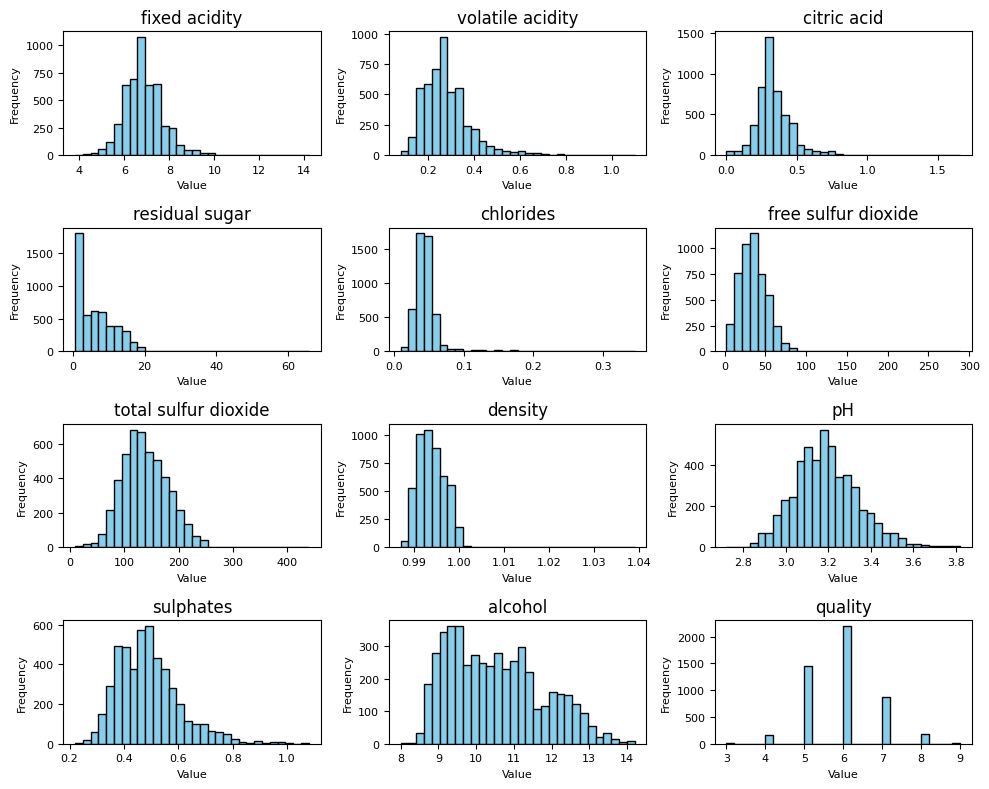

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(10, 8))
axes = axes.flatten()

for idx, col in enumerate(white_wines.columns):
    axes[idx].hist(white_wines[col], bins=30, color='skyblue', edgecolor='black')
    axes[idx].set_title(col)
    axes[idx].set_xlabel('Value', fontsize=8)
    axes[idx].set_ylabel('Frequency', fontsize=8)
    axes[idx].tick_params(labelsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# Normalize each column in the white_wines DataFrame by dividing by its mean
white_wines_normalized = white_wines / white_wines.mean()

# Display the first few rows of the normalized DataFrame
display(white_wines_normalized.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,1.021184,0.970381,1.077227,3.238720,0.983126,1.274496,1.228673,1.007015,0.940950,0.918654,0.836958,1.020771
1,0.919066,1.078202,1.017381,0.250336,1.070515,0.396510,0.954028,0.999972,1.035045,1.000313,0.903534,1.020771
2,1.181656,1.006321,1.196919,1.079573,1.092362,0.849664,0.701066,1.001079,1.022499,0.898240,0.960600,1.020771
3,1.050361,0.826621,0.957535,1.329909,1.267140,1.331140,1.344313,1.001582,1.000544,0.816582,0.941578,1.020771
4,1.050361,0.826621,0.957535,1.329909,1.267140,1.331140,1.344313,1.001582,1.000544,0.816582,0.941578,1.020771


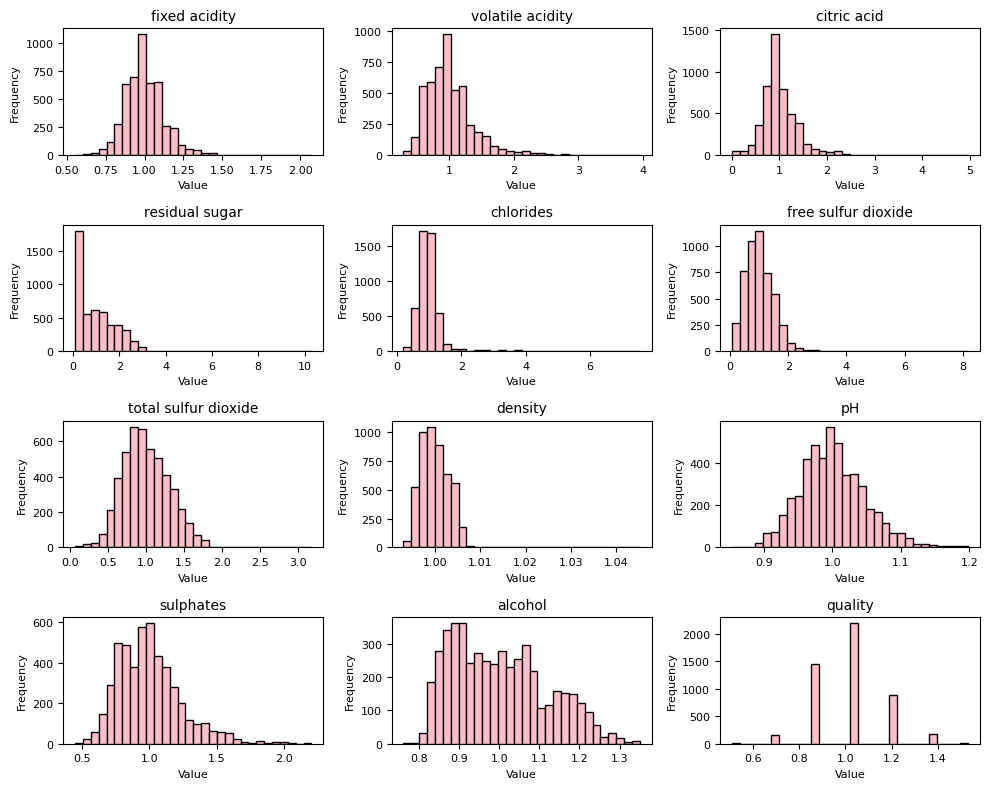

In [ ]:
#Plot a histogram of the distribution of each of these 12 normalized features.
#How do these histograms compare to the previous ones?

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(10, 8))
axes = axes.flatten()

for idx, col in enumerate(white_wines_normalized.columns):
    axes[idx].hist(white_wines_normalized[col], bins=30, color='pink', edgecolor='black')
    axes[idx].set_title(col, fontsize=10)
    axes[idx].set_xlabel('Value', fontsize=8)
    axes[idx].set_ylabel('Frequency', fontsize=8)
    axes[idx].tick_params(labelsize=8)

plt.tight_layout()
plt.show()

The histogram plots of `white_wines_normalized` have the same distribution shape compared to the plots of `white_wines`. However, since the values are normalized, the mean of each feature is centered at $1.0$. Some features like `residual sugar` or `chlorides` now show their main peak near $1.0$, with a long tail extending out to $3.0$ or higher.

In [ ]:
# 4. Compute the sum of the 12 normalized features for each of the 4898 white wines in the dataset
wine_sums = white_wines_normalized.sum(axis=1)

# Display the first few rows to verify
wine_sums.head()
wine_sums.shape
np.dtype(wine_sums)

dtype('float64')

Text(0, 0.5, 'Frequency')

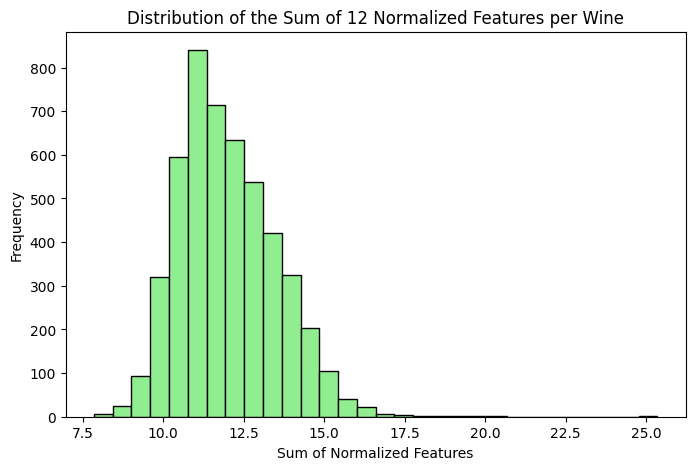

In [ ]:
# 4. Plot a histogram of the distribution of this sum. Does it look normally distributed?
plt.figure(figsize=(8, 5))
plt.hist(wine_sums, bins=30, color='lightgreen', edgecolor='black')
plt.title('Distribution of the Sum of 12 Normalized Features per Wine')
plt.xlabel('Sum of Normalized Features')
plt.ylabel('Frequency')

 5. Similarly to the in-class exercise, use the Central Limit Theorem to compute the Normal distribution to which this sum should converge. What is the expected mean of that Normal distribution? What is the population variance?

In [ ]:
# Create the Normal distribution predicted by the CLT: N(mu, sigma^2 / n).

# Since each of the 12 features was normalized by its mean, each has an expected mean of 1.0.
# Thus, the expected mean of their sum is 12.0.

mu_expected = 12.0
pop_variance = wine_sums.std(ddof = 0)
x = np.linspace(min(wine_sums), max(wine_sums), 1000)
y_normal = stats.norm.pdf(x, loc=mu_expected, scale=pop_variance)

print(f"Theoretical (Expected) Mean: {mu_expected}")
print(f"The population variance of the sum of the 12 normalized features is: {pop_variance:.6f}")

Theoretical (Expected) Mean: 12.0
The population variance of the sum of the 12 normalized features is: 1.511901


1.
We first normalized the data by taking every individual mean in that column and dividing it by the mean value of the entire column, repeat for every columns in `white_wines`. To find the average (or expected value) of a normalized column, we calculate the sum of all the normalized values and divide by the total number of wines.

Since Average of Normalized Column = (Average of Original Column) / (Mean of Column) = $1$

Therefore, the normalized mean of 12 features across all wines is: $$1.0 * 12 = 12$$

2. The population variance of `wine_sums` is $1.511901$.

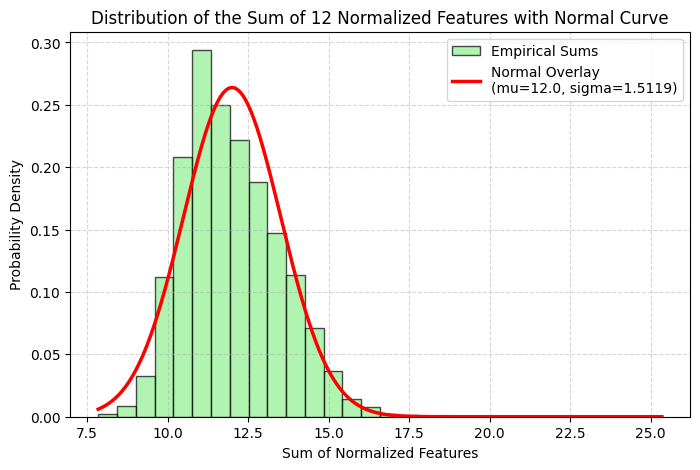

In [ ]:
# Plot the histogram of wine_sums as a density plot (probability density scale)
plt.figure(figsize=(8, 5))
plt.hist(wine_sums, bins=30, density=True, color='lightgreen', edgecolor='black', alpha=0.7, label='Empirical Sums')

# Overlay the Normal distribution curve with plain text label instead of LaTeX
plt.plot(x, y_normal, color='red', linewidth=2.5, label=f'Normal Overlay\n(mu={mu_expected:.1f}, sigma={pop_variance:.4f})')

# Labels and legend
plt.title('Distribution of the Sum of 12 Normalized Features with Normal Curve')
plt.xlabel('Sum of Normalized Features')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

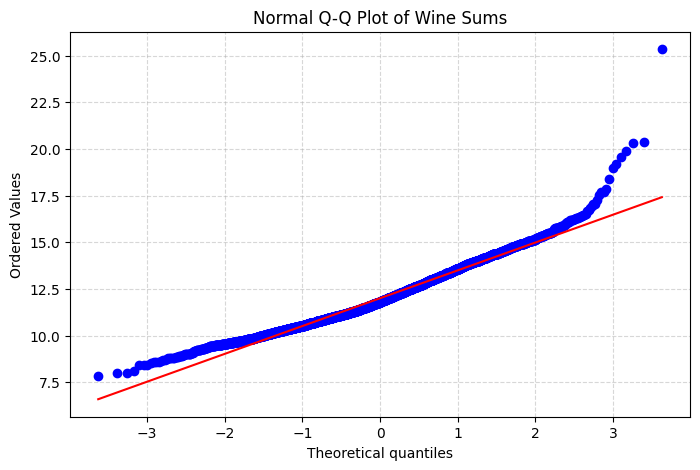

In [ ]:
# Create a Q-Q plot to visualize deviations from the Normal distribution
plt.figure(figsize=(8, 5))
stats.probplot(wine_sums, dist="norm", plot=plt)

# Customize titles and labels without using LaTeX
plt.title('Normal Q-Q Plot of Wine Sums')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

The histogram plot closely matches the histogram. Since the mean is a linear combination of the sum, the CLT states that the sum of a sufficiently large number of independent (or weakly dependent) random variables will tend toward a Normal distribution, regardless of the shape of the original distributions.

While the 12 features in the wine dataset are not completely independent (e.g., density is correlated with alcohol and sugar), they still carry independent sources of variation.

Looking at the Q-Q plot, we can also see that there is a strong center agreement, with the bulk of `wine_sums` lies on the straight diagonal line. However, the left-tail suggests that the lowest actual values of `wines_sum` are slighlty lower than the predicted Normal distribution, and the right tail suggests that the highest actual values of `wines_sum` are slightly larger than the predicted Normal distribution.

## Part 2: Central Limit Theorem with the product

In [ ]:
# Compute the product of the 12 normalized features for each of the 4898 white wines
wine_products = white_wines_normalized.prod(axis=1)

# Display the first few rows to verify the calculation
wine_products.head()
wine_products.shape

(4898,)

Text(0, 0.5, 'Frequency')

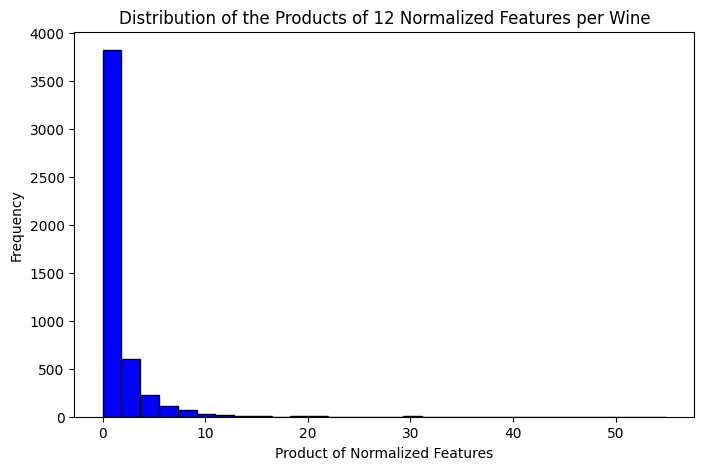

In [ ]:
# Plot a histogram of the distribution of this product
plt.figure(figsize=(8, 5))
plt.hist(wine_products, bins=30, color='blue', edgecolor='black')
plt.title('Distribution of the Products of 12 Normalized Features per Wine')
plt.xlabel('Product of Normalized Features')
plt.ylabel('Frequency')


This plot is not normally distributed, since this plot doesn't follow a symmetric bell curve.

In [ ]:
# Compute the logarithm (either base 10 or natural log) of the product
# of the 12 normalized features for each of the 4898 white wines in the dataset

wine_log_products = np.log10(wine_products)

# Display the first few rows to verify the calculation
wine_log_products.head()
wine_log_products.shape

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


(4898,)

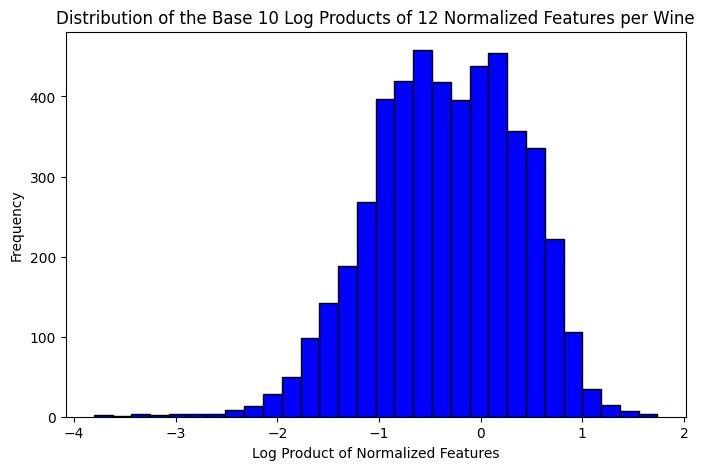

In [ ]:
# Filter out any non-finite values (such as -inf from log10(0))
clean_log_products = wine_log_products[np.isfinite(wine_log_products)]
clean_log_products.shape
# remove 19 observations
# Plot a histogram of the distribution of these values
plt.figure(figsize=(8, 5))
plt.hist(clean_log_products, bins=30, color='blue', edgecolor='black')
plt.title('Distribution of the Base 10 Log Products of 12 Normalized Features per Wine')
plt.xlabel('Log Product of Normalized Features')
plt.ylabel('Frequency')
plt.show()

This histogram of Base 10 Log Products distribution looks close to a Normal distribution, but it is heavy right skewed.
The plot of Base 10 Log Products is approaching a log-normal distribution.



**3 interesting facts about log-normal distribution:**
1. The lognormal distribution produces only positive values. The shape has a sharp rise from zero, a peak somewhere to the left of the mean, then a long tapering tail.

2. Mean, mode, and median of a log-normal distribution are not equal.

3. Log-normal distribution is heavy-right skewed.

**AI reflection**

For this assignment, I asked AI to help me validate my observations with the plots, and to help me understand more about the result. One prompt I used is:
- "Interpret the Q-Q plot and identify if there are significant tail deviations"
- AI didn't produce any oversimplifications this time, and the explanation look consistent with what I validated from other web sources. I don't have to correct or add anything by myself.